# B5. Khám phá dữ liệu (EDA)

Chỉ dùng **khách tập train** (246.008 hồ sơ, `ml/data/split.csv` từ notebook 03) và các dòng của 6 bảng phụ thuộc những khách này,
đọc từ `ml/data/clean/` (đã làm sạch ở notebook 04). Bỏ `CODE_GENDER` (khoản 2 Điều 6 QĐ-26).
Notebook chỉ **mô tả**: không loại cột, không đặt ngưỡng; các điểm cần quyết định gom ở mục cuối, chuyển sang B6.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
CLEAN_DIR = ROOT / "ml" / "data" / "clean"
FIG_DIR = ROOT / "ml" / "hinh"
FIG_DIR.mkdir(parents=True, exist_ok=True)
INK, MUTED, BLUE, GRID = "#0b0b0b", "#52514e", "#2a78d6", "#e4e3df"
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

s = pd.read_csv(ROOT / "ml" / "data" / "split.csv")
ids = set(s.SK_ID_CURR[s.tap == "train"])


def load(name):
    d = pd.read_parquet(CLEAN_DIR / f"{name}.parquet")
    return d[d.SK_ID_CURR.isin(ids)].reset_index(drop=True)


a = load("application_train").drop(columns="CODE_GENDER")
y = a.set_index("SK_ID_CURR").TARGET
base = y.mean()
a.shape

(246008, 122)

## 1. Biến mục tiêu

In [2]:
print(f"{len(y):,} hồ sơ; TARGET=1: {y.sum():,} ({base:.4%}); cứ {(1 - base) / base:.1f} hồ sơ 0 mới có 1 hồ sơ 1")

246,008 hồ sơ; TARGET=1: 19,860 (8.0729%); cứ 11.4 hồ sơ 0 mới có 1 hồ sơ 1


## 2. Giá trị thiếu

Nếu thiếu là MCAR thì nhóm thiếu và nhóm có phải giống nhau ở mọi mặt, kể cả tỷ lệ TARGET. Tỷ lệ TARGET khác nhau rõ → bác MCAR:
việc thiếu tự nó mang thông tin, cách xử lý phải giữ thông tin đó. 47 cột tòa nhà (`_AVG`, `_MODE`, `_MEDI`) xem chung một nhóm.

In [3]:
m = a.drop(columns=["SK_ID_CURR", "TARGET"]).isna()
r = m.mean().sort_values(ascending=False)
print(f"{(r > 0).sum()}/{len(r)} cột có thiếu: > 50% {(r > 0.5).sum()}; 10–50% {((r > 0.1) & (r <= 0.5)).sum()}; 0–10% {((r > 0) & (r <= 0.1)).sum()}")
print(f"số cột thiếu mỗi hồ sơ: trung vị {m.sum(axis=1).median():.0f}, p90 {m.sum(axis=1).quantile(0.9):.0f}")
build = [c for c in r.index if c.endswith(("_AVG", "_MODE", "_MEDI"))]
all_build = m[build].all(axis=1)
print(f"{len(build)} cột tòa nhà thiếu {r[build].min():.2%}–{r[build].max():.2%}; hồ sơ thiếu toàn bộ nhóm {all_build.mean():.2%}")

t = pd.DataFrame({c: {"tỷ lệ thiếu": r[c], "TARGET khi thiếu": a.TARGET[m[c]].mean(), "TARGET khi có": a.TARGET[~m[c]].mean()}
                  for c in r.index if r[c] > 0.01 and c not in build}).T
t.loc["(thiếu toàn bộ 47 cột tòa nhà)"] = [all_build.mean(), a.TARGET[all_build].mean(), a.TARGET[~all_build].mean()]
t["chênh (điểm %)"] = (t["TARGET khi thiếu"] - t["TARGET khi có"]) * 100
t

70/120 cột có thiếu: > 50% 41; 10–50% 18; 0–10% 11
số cột thiếu mỗi hồ sơ: trung vị 37, p90 52
47 cột tòa nhà thiếu 47.39%–69.84%; hồ sơ thiếu toàn bộ nhóm 47.39%


,tỷ lệ thiếu,TARGET khi thiếu,TARGET khi có,chênh (điểm %)
OWN_CAR_AGE,0.6602,0.0848,0.0727,1.2089
EXT_SOURCE_1,0.5634,0.0852,0.0749,1.0351
OCCUPATION_TYPE,0.3128,0.0649,0.0879,-2.3002
EXT_SOURCE_3,0.1984,0.0928,0.0777,1.5030
DAYS_EMPLOYED,0.1794,0.0537,0.0866,-3.2953
ORGANIZATION_TYPE,0.1794,0.0537,0.0866,-3.2953
AMT_REQ_CREDIT_BUREAU_HOUR,0.1351,0.1034,0.0772,2.6198
AMT_REQ_CREDIT_BUREAU_QRT,0.1351,0.1034,0.0772,2.6198
AMT_REQ_CREDIT_BUREAU_YEAR,0.1351,0.1034,0.0772,2.6198
AMT_REQ_CREDIT_BUREAU_WEEK,0.1351,0.1034,0.0772,2.6198


In [4]:
occ = a.OCCUPATION_TYPE.isna()
print(f"OCCUPATION_TYPE thiếu {occ.sum():,}; trong đó không đi làm {(occ & (a.FLAG_NOT_EMPLOYED == 1)).sum():,} ({(a.FLAG_NOT_EMPLOYED == 1)[occ].mean():.2%})")

OCCUPATION_TYPE thiếu 76,940; trong đó không đi làm 44,141 (57.37%)


## 3. Phân bố và quan hệ với TARGET

Cột tính thêm (đúng bảng khớp): tuổi, thâm niên (năm); **PTI** = tiền trả tháng / thu nhập tháng; vay / thu nhập; **vay / trả kỳ**
(xấp xỉ số kỳ; vì tiền trả kỳ đã gồm lãi, cùng kỳ hạn thì lãi suất cao hơn cho tỷ lệ này nhỏ hơn — đây là chỗ đội hạng 2 suy ra lãi suất).

Chia mỗi cột thành 10 nhóm cùng số hồ sơ (thập phân vị), tính tỷ lệ TARGET mỗi nhóm: tăng/giảm đều là quan hệ **đơn điệu**;
cao ở giữa thấp hai đầu thì một hệ số tuyến tính của LR không mô tả được. "lệch" = skewness (0 cân đối, dương lớn = đuôi phải dài).

In [5]:
d = pd.DataFrame({
    "tuổi (năm)": -a.DAYS_BIRTH / 365.25,
    "thâm niên (năm)": -a.DAYS_EMPLOYED / 365.25,
    "PTI": a.AMT_ANNUITY / a.AMT_INCOME_TOTAL,
    "vay / thu nhập": a.AMT_CREDIT / a.AMT_INCOME_TOTAL,
    "vay / trả kỳ": a.AMT_CREDIT / a.AMT_ANNUITY,
    **{c: a[c] for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]},
})
dec, rows = {}, {}
for c in d:
    b = pd.qcut(d[c], 10, duplicates="drop")
    dec[c] = (d[c].groupby(b, observed=True).median(), a.TARGET.groupby(b, observed=True).mean())
    q = d[c].quantile([0.01, 0.5, 0.99])
    rows[c] = {"thiếu": d[c].isna().mean(), "p1": q[0.01], "p50": q[0.5], "p99": q[0.99], "max": d[c].max(), "lệch": d[c].skew(),
               "TARGET tpv 1": dec[c][1].iloc[0], "TARGET tpv 10": dec[c][1].iloc[-1],
               "TARGET min–max": f"{dec[c][1].min():.3f}–{dec[c][1].max():.3f}"}
pd.DataFrame(rows).T

,thiếu,p1,p50,p99,max,lệch,TARGET tpv 1,TARGET tpv 10,TARGET min–max
tuổi (năm),0.0000,22.6146,43.1047,66.8364,69.0732,0.1158,0.1165,0.0488,0.049–0.117
thâm niên (năm),0.1794,0.3039,4.5120,31.0445,49.0404,1.9650,0.1104,0.0448,0.045–0.116
PTI,0.0000,0.0394,0.1628,0.4839,1.5706,1.4975,0.0707,0.0828,0.071–0.089
vay / thu nhập,0.0000,0.5958,3.2689,13.0357,49.2272,1.7575,0.0684,0.0714,0.068–0.092
vay / trả kỳ,0.0000,8.7337,20.0000,37.7946,45.3051,0.3038,0.0492,0.0576,0.049–0.142
EXT_SOURCE_1,0.5634,0.0836,0.5054,0.8901,0.9516,-0.0657,0.1741,0.0258,0.026–0.174
EXT_SOURCE_2,0.0022,0.0290,0.5659,0.7827,0.8550,-0.7943,0.1828,0.0296,0.030–0.183
EXT_SOURCE_3,0.1984,0.0647,0.5353,0.8338,0.8960,-0.4100,0.1992,0.0326,0.033–0.199
AMT_INCOME_TOTAL,0.0000,"45,000.0000","147,600.0000","472,500.0000","117,000,000.0000",375.1281,0.0834,0.0609,0.061–0.091
AMT_CREDIT,0.0000,"76,410.0000","514,777.5000","1,862,802.0000","4,050,000.0000",1.2339,0.0673,0.0539,0.054–0.104


In [6]:
pd.DataFrame({c: dec[c][1].values for c in d}, index=range(1, 11)).T.rename_axis("TARGET theo thập phân vị")

,1,2,3,4,5,6,7,8,9,10
TARGET theo thập phân vị,,,,,,,,,,
tuổi (năm),0.1165,0.1103,0.0982,0.0883,0.0804,0.0772,0.0706,0.0632,0.0539,0.0488
thâm niên (năm),0.1104,0.1160,0.1095,0.1031,0.0945,0.0842,0.0757,0.0695,0.0584,0.0448
PTI,0.0707,0.0727,0.0789,0.0781,0.0787,0.0828,0.0849,0.0883,0.0895,0.0828
vay / thu nhập,0.0684,0.0780,0.0809,0.0916,0.0868,0.0914,0.0871,0.0779,0.0739,0.0714
vay / trả kỳ,0.0492,0.1138,0.0982,0.1006,0.0587,0.1417,0.0513,0.0736,0.0704,0.0576
EXT_SOURCE_1,0.1741,0.1164,0.0913,0.0844,0.0681,0.0596,0.0517,0.0434,0.0342,0.0258
EXT_SOURCE_2,0.1828,0.1210,0.0987,0.0841,0.0747,0.0656,0.0585,0.0503,0.0421,0.0296
EXT_SOURCE_3,0.1992,0.1277,0.0978,0.0794,0.0618,0.0534,0.0484,0.0410,0.0348,0.0326
AMT_INCOME_TOTAL,0.0834,0.0820,0.0875,0.0846,0.0907,0.0853,0.0845,0.0782,0.0697,0.0609


"vay / trả kỳ" có hình răng cưa (lên xuống giữa các thập phân vị kề nhau), khác hẳn các cột khác. Xem theo 40 nhóm nhỏ hơn và theo loại hợp đồng:
nếu khoản vay có một số kỳ hạn cố định (12, 24, 36... tháng) thì tỷ lệ này tụ thành từng cụm theo kỳ hạn, trong mỗi cụm vị trí phản ánh lãi suất.

In [7]:
cash = a.NAME_CONTRACT_TYPE == "Cash loans"
ratio = d["vay / trả kỳ"][cash]
b = pd.qcut(ratio, 40, duplicates="drop")
t = a.TARGET[cash].groupby(b, observed=True).agg(["size", "mean"]).set_axis(["số hồ sơ", "TARGET"], axis=1)
t.index = [f"{iv.left:.2f}–{iv.right:.2f}" for iv in t.index]
print("Revolving: vay / trả kỳ =", d["vay / trả kỳ"][~cash].round(2).value_counts().head(3).to_dict())
t

Revolving: vay / trả kỳ = {20.0: 23413, 10.0: 35}


,số hồ sơ,TARGET
8.04–9.24,5578,0.0878
9.24–9.48,5552,0.0661
9.48–10.05,5562,0.0270
10.05–10.24,5609,0.0237
10.24–11.59,5518,0.0654
11.59–12.60,5574,0.1417
12.60–12.83,5575,0.1772
12.83–13.78,5542,0.0989
13.78–14.72,5565,0.0749
14.72–14.96,5570,0.1377


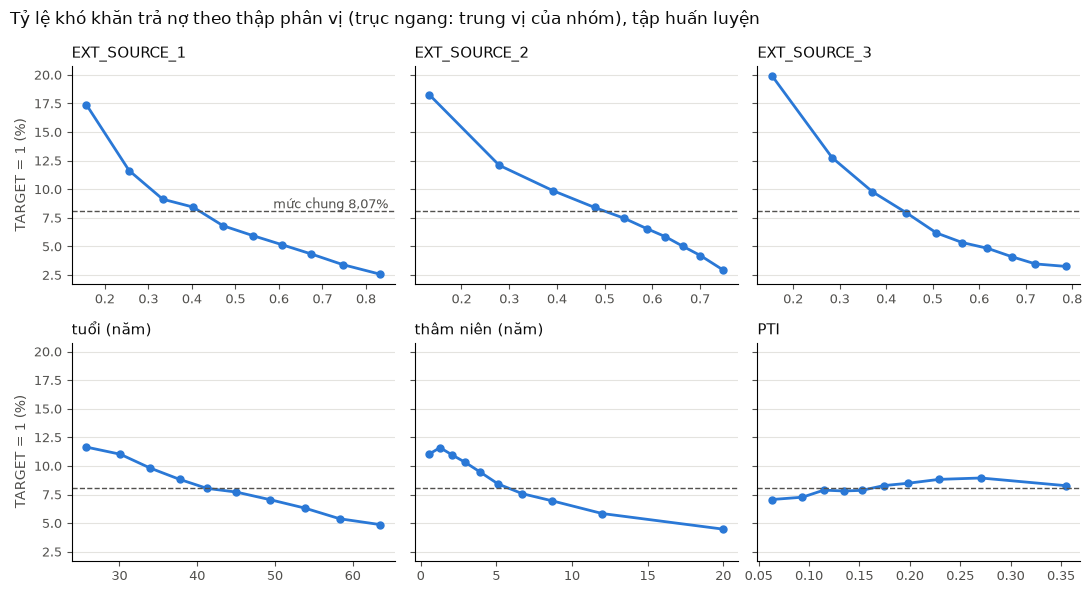

In [8]:
cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "tuổi (năm)", "thâm niên (năm)", "PTI"]
fig, ax = plt.subplots(2, 3, figsize=(11, 6), sharey=True)
for p, c in zip(ax.flat, cols):
    x, t = dec[c]
    p.plot(x.values, t.values * 100, color=BLUE, lw=2, marker="o", ms=5)
    p.axhline(base * 100, color=MUTED, lw=1, ls="--")
    p.set_title(c, color=INK, fontsize=11, loc="left")
    p.grid(axis="y", color=GRID, lw=0.8)
    p.tick_params(colors=MUTED, labelsize=9)
    p.spines[["top", "right"]].set_visible(False)
for p in ax[:, 0]:
    p.set_ylabel("TARGET = 1 (%)", color=MUTED)
ax[0, 0].annotate(f"mức chung {base:.2%}".replace(".", ","), (0.98, base * 100), xycoords=("axes fraction", "data"),
                  ha="right", va="bottom", color=MUTED, fontsize=9)
fig.suptitle("Tỷ lệ khó khăn trả nợ theo thập phân vị (trục ngang: trung vị của nhóm), tập huấn luyện", color=INK, fontsize=12, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "ml_eda_thap_phan_vi.png", dpi=150)

## 4. Tỷ lệ TARGET theo nhóm

Chỉ hiện nhóm ≥ 1.000 hồ sơ (nhóm nhỏ dao động ngẫu nhiên nhiều). Cuối mục: các mốc chính sách AT Credit (tuổi, PTI > 40%, thâm niên < 6 tháng).

In [9]:
def rate(g, yy=a.TARGET, min_n=1000):
    t = yy.groupby(g, observed=True).agg(["size", "mean"]).set_axis(["số hồ sơ", "TARGET"], axis=1)
    return t[t["số hồ sơ"] >= min_n]


CATS = ["NAME_CONTRACT_TYPE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE",
        "OCCUPATION_TYPE", "REGION_RATING_CLIENT", "FLAG_OWN_CAR", "FLAG_OWN_REALTY"]
pd.concat({c: rate(a[c].fillna("(trống)")).sort_values("TARGET") for c in CATS})

số hồ sơ  TARGET
NAME_CONTRACT_TYPE   Revolving loans                   23448  0.0549
                     Cash loans                       222560  0.0834
NAME_INCOME_TYPE     Pensioner                         44134  0.0536
                     State servant                     17518  0.0585
                     Commercial associate              57273  0.0759
                     Working                          127043  0.0954
NAME_EDUCATION_TYPE  Higher education                  59802  0.0539
                     Incomplete higher                  8289  0.0863
                     Secondary / secondary special    174768  0.0892
                     Lower secondary                    3025  0.1107
NAME_FAMILY_STATUS   Widow                             12842  0.0587
                     Married                          157153  0.0753
                     Separated                         15840  0.0799
                     Single / not married              36359  0.0995
                     Civil marriage                    23812  0.1002
NAME_HOUSING_TYPE    Office apartment                   2097  0.0649
                     House / apartment                218383  0.0779
                     Municipal apartment                8916  0.0850
                     With parents                      11857  0.1172
                     Rented apartment                   3873  0.1234
OCCUPATION_TYPE      Accountants                        7882  0.0463
                     Managers                          17096  0.0622
                     High skill tech staff              9093  0.0628
                     Core staff                        22093  0.0638
                     (trống)                           76940  0.0649
                     Private service staff              2094  0.0659
                     Medicine staff                     6871  0.0699
                     Secretaries                        1047  0.0716
                     Cleaning staff                     3741  0.0954
                     Sales staff                       25606  0.0960
                     Cooking staff                      4767  0.1051
                     Laborers                          44259  0.1052
                     Security staff                     5372  0.1069
                     Drivers                           14944  0.1126
                     Waiters/barmen staff               1046  0.1147
                     Low-skill Laborers                 1696  0.1810
REGION_RATING_CLIENT 1                                 25755  0.0485
                     2                                181631  0.0788
                     3                                 38622  0.1113
FLAG_OWN_CAR         Y                                 83595  0.0727
                     N                                162413  0.0848
FLAG_OWN_REALTY      Y                                170690  0.0797
                     N                                 75318  0.0831

In [10]:
emp = pd.cut(d["thâm niên (năm)"], [0, 0.5, 1, 3, 5, 10, 50], right=False).cat.add_categories("không đi làm").fillna("không đi làm")
pd.concat({
    "tuổi": rate(pd.cut(d["tuổi (năm)"], [0, 25, 30, 40, 50, 60, 71], right=False).astype(str)),
    "PTI": rate(np.where(d.PTI > 0.4, "PTI > 40%", "PTI ≤ 40%")),
    "thâm niên (năm)": rate(emp.astype(str)).reindex(emp.cat.categories.astype(str)),
})

số hồ sơ  TARGET
tuổi            [0, 25)           9841  0.1244
                [25, 30)         26440  0.1112
                [30, 40)         65844  0.0960
                [40, 50)         61296  0.0766
                [50, 60)         54477  0.0606
                [60, 71)         28110  0.0491
PTI             PTI > 40%         6330  0.0839
                PTI ≤ 40%       239678  0.0806
thâm niên (năm) [0.0, 0.5)        7766  0.1060
                [0.5, 1.0)       14627  0.1121
                [1.0, 3.0)       49260  0.1106
                [3.0, 5.0)       37558  0.0962
                [5.0, 10.0)      51877  0.0743
                [10.0, 50.0)     40777  0.0517
                không đi làm     44143  0.0537

## 5. Gom sáu bảng phụ về mức khách

Mỗi bảng phụ nhiều dòng/khách; muốn so với TARGET phải gom về một giá trị mỗi khách. Ở đây gom vừa đủ để khám phá, **đúng định nghĩa bảng khớp mục 7**
(đặc trưng thật làm ở B6):

| Bảng | Dấu hiệu (có / không) | Tổng hợp số (cho IV ở mục 6) |
|---|---|---|
| `bureau` | Khoản Active quá hạn ≥ 10 / > 90 ngày (`CREDIT_DAY_OVERDUE`) | số khoản Active, max ngày quá hạn Active, tổng dư nợ Active, ngày mở khoản gần nhất |
| `bureau_balance` | Từng có STATUS 1–5 / 2–5 / 4–5 | (thời điểm, mục 8) |
| `previous_application` | Từng bị từ chối | số hồ sơ cũ, số bị từ chối, tỷ lệ bị từ chối |
| `POS_CASH_balance`, `credit_card_balance` | Từng có tháng `SK_DPD` ≥ 10 / > 90 (không dùng `SK_DPD_DEF`) | max `SK_DPD`; AT Flex: tỷ lệ sử dụng hạn mức trung bình (hạn mức = 0 → trống) |
| `installments_payments` | Từng có kỳ quá hạn ≥ 10 / > 90 ngày (QC-01) | max ngày quá hạn, tỷ lệ kỳ quá hạn ≥ 10 ngày |

Khách không có dữ liệu ở một bảng: dấu hiệu và tổng hợp để **trống** (không ghi 0), vì "không có thông tin" khác "không quá hạn".
Thời điểm quá hạn gần nhất tính theo tháng trước ngày nộp, dùng ở mục 8.

In [11]:
f, agg, last, cov = {}, {}, {}, {}
b = load("bureau")
cov["bureau"] = b.SK_ID_CURR.unique()
act = b[b.CREDIT_ACTIVE == "Active"]
g = act.groupby("SK_ID_CURR")
od = g.CREDIT_DAY_OVERDUE.max().reindex(cov["bureau"], fill_value=0)  # có bureau, không khoản Active: 0
f["CIC: khoản Active quá hạn ≥ 10 ngày"] = od >= 10
f["CIC: khoản Active quá hạn > 90 ngày"] = od > 90
agg["CIC: số khoản Active"] = g.size().reindex(cov["bureau"], fill_value=0)
agg["CIC: max ngày quá hạn khoản Active"] = od
agg["CIC: tổng dư nợ khoản Active"] = g.AMT_CREDIT_SUM_DEBT.sum().reindex(cov["bureau"], fill_value=0)
agg["CIC: ngày mở khoản gần nhất"] = b.groupby("SK_ID_CURR").DAYS_CREDIT.max()

bb = pd.read_parquet(CLEAN_DIR / "bureau_balance.parquet").merge(b[["SK_ID_BUREAU", "SK_ID_CURR"]], on="SK_ID_BUREAU")
cov["bureau_balance"] = bb.SK_ID_CURR.unique()
for st, name in [("12345", "từng có tháng quá hạn (STATUS 1–5)"), ("2345", "từng quá hạn > 30 ngày (STATUS 2–5)"), ("45", "từng nợ xấu (STATUS 4–5)")]:
    f[f"CIC tháng: {name}"] = bb.STATUS.isin(list(st)).groupby(bb.SK_ID_CURR).any()
h = bb[bb.STATUS.isin(list("12345"))]
last["CIC tháng: STATUS 1–5"] = (-h.groupby("SK_ID_CURR").MONTHS_BALANCE.max(), cov["bureau_balance"])
del bb, b, act, h

p = load("previous_application")
cov["previous_application"] = p.SK_ID_CURR.unique()
ref = (p.NAME_CONTRACT_STATUS == "Refused").groupby(p.SK_ID_CURR)
f["AT Credit: từng bị từ chối"] = ref.any()
agg["AT Credit: số hồ sơ cũ"] = p.groupby("SK_ID_CURR").size()
agg["AT Credit: số hồ sơ bị từ chối"] = ref.sum()
agg["AT Credit: tỷ lệ hồ sơ bị từ chối"] = ref.mean()
del p

In [12]:
monthly = {}
for name, lab in [("POS_CASH_balance", "trả góp cũ"), ("credit_card_balance", "AT Flex cũ")]:
    dm = monthly[name] = load(name)
    cov[name] = dm.SK_ID_CURR.unique()
    mx = dm.groupby("SK_ID_CURR").SK_DPD.max()
    f[f"khoản {lab}: tháng SK_DPD ≥ 10"] = mx >= 10
    f[f"khoản {lab}: tháng SK_DPD > 90"] = mx > 90
    agg[f"khoản {lab}: max SK_DPD"] = mx
    last[f"khoản {lab}: tháng SK_DPD ≥ 10"] = (-dm[dm.SK_DPD >= 10].groupby("SK_ID_CURR").MONTHS_BALANCE.max(), cov[name])
cc = monthly["credit_card_balance"]
agg["khoản AT Flex cũ: tỷ lệ sử dụng hạn mức TB"] = (cc.AMT_BALANCE / cc.AMT_CREDIT_LIMIT_ACTUAL.where(cc.AMT_CREDIT_LIMIT_ACTUAL > 0)).groupby(cc.SK_ID_CURR).mean()

Ngày quá hạn một kỳ theo khoản 7 Điều 2 QC-01: sắp các lần trả của kỳ theo ngày, cộng dồn; **ngày trả đủ** là ngày của lần trả làm tổng đạt
số phải trả (sai số 1 đơn vị). Quá hạn = max(0, ngày trả đủ − ngày đến hạn). Kỳ chưa trả đủ trước ngày nộp: quá hạn đến ngày nộp (ngày 0);
cách tính này còn chờ việc mở 0b(ii), ảnh hưởng 0,044% số kỳ.

In [13]:
ip = load("installments_payments")
cov["installments_payments"] = ip.SK_ID_CURR.unique()
# một kỳ = (khoản, số kỳ, ngày đến hạn): số phải trả cộng qua các phiên bản lịch, lần trả ghi lặp ở mỗi phiên bản chỉ tính một lần
k = ["SK_ID_PREV", "NUM_INSTALMENT_NUMBER", "DAYS_INSTALMENT"]
can = ip.drop_duplicates(k + ["NUM_INSTALMENT_VERSION"]).groupby(k).AMT_INSTALMENT.sum()
can = can[can > 0]  # Home Credit (57562): kỳ phải trả 0 bỏ qua
ip = ip.drop_duplicates(k + ["DAYS_ENTRY_PAYMENT", "AMT_PAYMENT"]).sort_values(k + ["DAYS_ENTRY_PAYMENT"])
ip["cum"] = ip.groupby(k).AMT_PAYMENT.cumsum()
ip = ip.join(can.rename("can"), on=k)
ky = can.to_frame("can").join(ip.groupby(k).SK_ID_CURR.first().rename("cur"))
ky["du"] = ip[ip.cum >= ip.can - 1].groupby(k).DAYS_ENTRY_PAYMENT.min()
# chưa trả đủ: quá hạn tới ngày kết thúc hợp đồng nếu đã kết thúc, chưa kết thúc thì tới ngày nộp
term = load("previous_application").set_index("SK_ID_PREV").DAYS_TERMINATION
end = term.reindex(ky.index.get_level_values("SK_ID_PREV")).clip(upper=0).fillna(0).values
han = ky.index.get_level_values("DAYS_INSTALMENT")
ky["dpd"] = (ky.du.fillna(pd.Series(end, index=ky.index)) - han).clip(lower=0)
gk = ky.groupby("cur")
f["kỳ trả nợ cũ: quá hạn ≥ 10 ngày"] = gk.dpd.max() >= 10
f["kỳ trả nợ cũ: quá hạn > 90 ngày"] = gk.dpd.max() > 90
agg["kỳ trả nợ cũ: max ngày quá hạn"] = gk.dpd.max()
agg["kỳ trả nợ cũ: tỷ lệ kỳ quá hạn ≥ 10 ngày"] = (ky.dpd >= 10).groupby(ky.cur).mean()
late = ky[ky.dpd >= 10]
last["kỳ trả nợ cũ: quá hạn ≥ 10 ngày"] = ((-pd.Series(late.index.get_level_values("DAYS_INSTALMENT"), index=late.index).groupby(late.cur).max() / 30.44).round(), cov["installments_payments"])
del ip, ky, late, term

In [14]:
pd.DataFrame({n: {"khách có dữ liệu": y.index.isin(c).mean(), "TARGET khi có": y[y.index.isin(c)].mean(),
                  "TARGET khi không có": y[~y.index.isin(c)].mean()} for n, c in cov.items()}).T

,khách có dữ liệu,TARGET khi có,TARGET khi không có
bureau,0.8567,0.0773,0.1012
bureau_balance,0.2994,0.0812,0.0805
previous_application,0.9464,0.0819,0.0600
POS_CASH_balance,0.9413,0.0816,0.0668
credit_card_balance,0.2833,0.0867,0.0784
installments_payments,0.9484,0.0819,0.0598


In [15]:
sig = {}
for c, v in f.items():
    v = v.astype(bool)
    yy = y[v.index]
    sig[c] = {"tỷ lệ khách (trong khách có dữ liệu bảng đó)": v.mean(), "TARGET khi có": yy[v].mean(), "TARGET khi không": yy[~v].mean()}
sig = pd.DataFrame(sig).T
sig

,tỷ lệ khách (trong khách có dữ liệu bảng đó),TARGET khi có,TARGET khi không
CIC: khoản Active quá hạn ≥ 10 ngày,0.0110,0.1548,0.0764
CIC: khoản Active quá hạn > 90 ngày,0.0036,0.1153,0.0772
CIC tháng: từng có tháng quá hạn (STATUS 1–5),0.3364,0.1002,0.0716
CIC tháng: từng quá hạn > 30 ngày (STATUS 2–5),0.0694,0.0986,0.0799
CIC tháng: từng nợ xấu (STATUS 4–5),0.0286,0.1136,0.0803
AT Credit: từng bị từ chối,0.3450,0.1034,0.0706
khoản trả góp cũ: tháng SK_DPD ≥ 10,0.0904,0.1024,0.0795
khoản trả góp cũ: tháng SK_DPD > 90,0.0161,0.0847,0.0815
khoản AT Flex cũ: tháng SK_DPD ≥ 10,0.0476,0.0989,0.0861
khoản AT Flex cũ: tháng SK_DPD > 90,0.0176,0.0676,0.0871


In [16]:
cnt = agg["CIC: số khoản Active"]
pd.concat({
    "số khoản CIC Active": rate(cnt.clip(upper=6).astype(str).replace("6", "≥ 6"), y[cnt.index]).sort_index(),
    "số hồ sơ cũ tại AT Credit": rate(agg["AT Credit: số hồ sơ cũ"].clip(upper=6).astype(str).replace("6", "≥ 6"), y[agg["AT Credit: số hồ sơ cũ"].index]).sort_index(),
})

số hồ sơ  TARGET
số khoản CIC Active       0       37034  0.0564
                          1       59116  0.0711
                          2       46859  0.0745
                          3       30476  0.0826
                          4       17645  0.0935
                          5        9662  0.1041
                          ≥ 6      9972  0.1343
số hồ sơ cũ tại AT Credit 1       41947  0.0827
                          2       36661  0.0785
                          3       32071  0.0787
                          4       26397  0.0754
                          5       21246  0.0794
                          ≥ 6     74512  0.0875

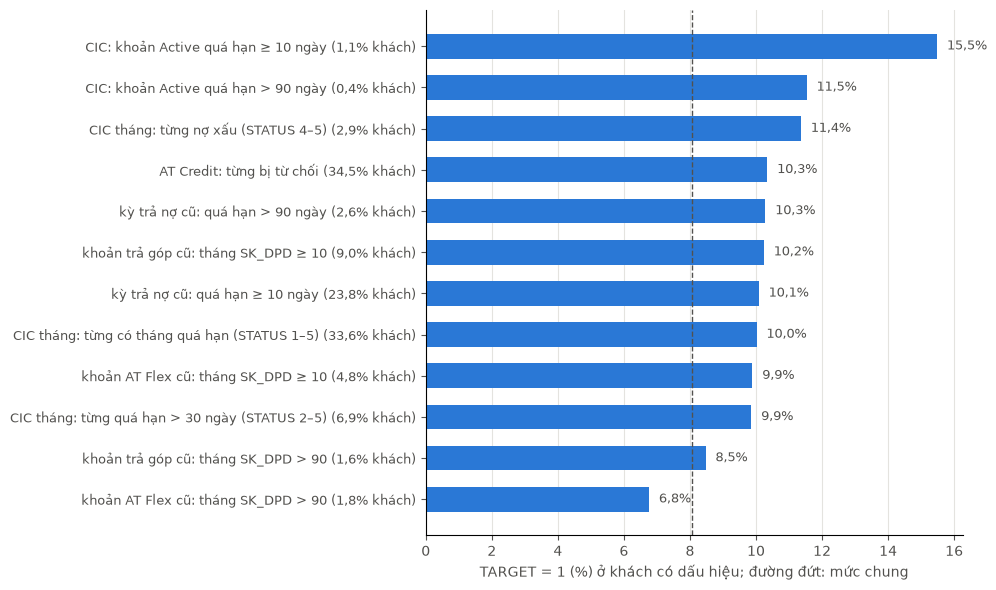

In [17]:
t = sig.sort_values("TARGET khi có")
fig, p = plt.subplots(figsize=(10, 6))
yy = np.arange(len(t))
p.barh(yy, t["TARGET khi có"] * 100, color=BLUE, height=0.6)
p.axvline(base * 100, color=MUTED, lw=1, ls="--")
p.set_yticks(yy, [f"{i} ({r.iloc[0]:.1%} khách)".replace(".", ",") for i, r in t.iterrows()], fontsize=9, color=INK)
for i, v in enumerate(t["TARGET khi có"]):
    p.text(v * 100 + 0.3, i, f"{v:.1%}".replace(".", ","), va="center", fontsize=9, color=MUTED)
p.set_xlabel("TARGET = 1 (%) ở khách có dấu hiệu; đường đứt: mức chung", color=MUTED)
p.grid(axis="x", color=GRID, lw=0.8)
p.set_axisbelow(True)
p.tick_params(colors=MUTED)
p.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "ml_eda_bang_phu.png", dpi=150)

## 6. Weight of Evidence và Information Value

Với mỗi cột, chia hồ sơ thành nhóm (cột số có > 10 giá trị: 10 nhóm cùng số hồ sơ; cột còn lại: từng giá trị; ô trống: một nhóm riêng). Với nhóm i:

- P(i | Y=1) = số hồ sơ TARGET=1 trong nhóm / tổng số hồ sơ TARGET=1 (19.860); P(i | Y=0) tương tự với 226.148 hồ sơ TARGET=0.
- **WoE_i = ln(P(i|Y=1) / P(i|Y=0))**: dương là nhóm nhiều hồ sơ khó khăn hơn mức chung, âm là ít hơn, 0 là bằng mức chung.
- **IV = Σ (P(i|Y=1) − P(i|Y=0)) · WoE_i** ≥ 0: tổng mức "khác biệt" của các nhóm; cột không liên quan TARGET cho IV ≈ 0.

Ví dụ đọc: nếu nhóm EXT_SOURCE_3 thấp nhất chứa 25% hồ sơ khó khăn nhưng chỉ 9% hồ sơ bình thường thì WoE = ln(25/9) ≈ 1,0, đóng góp (0,25 − 0,09) × 1,0 = 0,16 vào IV.

IV khác Spearman ở chỗ: không cần quan hệ đơn điệu (nhóm giữa cao vẫn được tính) và ô trống được tính như một nhóm.
Ô đếm bằng 0 được cộng 0,5 để tránh ln(0). Thang đọc (Siddiqi): < 0,02 không dự báo; 0,02–0,1 yếu; 0,1–0,3 trung bình; 0,3–0,5 mạnh; > 0,5 đáng ngờ.

In [18]:
N1, N0 = y.sum(), (1 - y).sum()


def woe_table(x, yy):
    x = pd.Series(x)
    if pd.api.types.is_numeric_dtype(x) and x.nunique() > 10:
        g = pd.qcut(x, 10, duplicates="drop")
    else:
        g = pd.Categorical(x.astype(str).where(x.notna()))
    g = pd.Series(g).cat.add_categories("(trống)").fillna("(trống)")
    t = pd.crosstab(g, yy).reindex(columns=[0, 1], fill_value=0).replace(0, 0.5)
    t["P(i|Y=1)"], t["P(i|Y=0)"] = t[1] / N1, t[0] / N0
    t["WoE"] = np.log(t["P(i|Y=1)"] / t["P(i|Y=0)"])
    t["IV_i"] = (t["P(i|Y=1)"] - t["P(i|Y=0)"]) * t["WoE"]
    return t


def level(v):
    return "đáng ngờ" if v > 0.5 else "mạnh" if v >= 0.3 else "trung bình" if v >= 0.1 else "yếu" if v >= 0.02 else "không dự báo"


cols = {c: a[c].values for c in a.columns if c not in ("SK_ID_CURR", "TARGET")}
cols |= {f"(tính) {c}": d[c].values for c in ["PTI", "vay / thu nhập", "vay / trả kỳ"]}
cols |= {f"(bảng phụ) {c}": v.reindex(y.index).values for c, v in agg.items()}
iv = pd.Series({c: woe_table(v, a.TARGET.values).IV_i.sum() for c, v in cols.items()}).sort_values(ascending=False)
ivt = iv.to_frame("IV").assign(mức=iv.map(level))
print(ivt.mức.value_counts().reindex(["đáng ngờ", "mạnh", "trung bình", "yếu", "không dự báo"], fill_value=0).to_dict())
ivt.head(30)

{'đáng ngờ': 0, 'mạnh': 2, 'trung bình': 3, 'yếu': 57, 'không dự báo': 73}


,IV,mức
EXT_SOURCE_3,0.3298,mạnh
EXT_SOURCE_2,0.3032,mạnh
EXT_SOURCE_1,0.1513,trung bình
(tính) vay / trả kỳ,0.1420,trung bình
DAYS_EMPLOYED,0.1116,trung bình
AMT_GOODS_PRICE,0.0914,yếu
DAYS_BIRTH,0.0868,yếu
(bảng phụ) CIC: ngày mở khoản gần nhất,0.0836,yếu
OCCUPATION_TYPE,0.0833,yếu
ORGANIZATION_TYPE,0.0752,yếu


In [19]:
# Đủ 135 cột
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 80):
    print(ivt.to_string())

                                                          IV           mức
EXT_SOURCE_3                                          0.3298          mạnh
EXT_SOURCE_2                                          0.3032          mạnh
EXT_SOURCE_1                                          0.1513    trung bình
(tính) vay / trả kỳ                                   0.1420    trung bình
DAYS_EMPLOYED                                         0.1116    trung bình
AMT_GOODS_PRICE                                       0.0914           yếu
DAYS_BIRTH                                            0.0868           yếu
(bảng phụ) CIC: ngày mở khoản gần nhất                0.0836           yếu
OCCUPATION_TYPE                                       0.0833           yếu
ORGANIZATION_TYPE                                     0.0752           yếu
(bảng phụ) AT Credit: tỷ lệ hồ sơ bị từ chối          0.0691           yếu
(bảng phụ) khoản AT Flex cũ: tỷ lệ sử dụng hạn mức TB 0.0657           yếu
NAME_INCOME_TYPE         

In [20]:
woe_table(a.EXT_SOURCE_3, a.TARGET.values).assign(TARGET=lambda t: t[1] / (t[0] + t[1]))

col_0,0,1,P(i|Y=1),P(i|Y=0),WoE,IV_i,TARGET
EXT_SOURCE_3,,,,,,,
"(-0.000473, 0.228]",15795,3928,0.1978,0.0698,1.0409,0.1332,0.1992
"(0.228, 0.33]",17234,2523,0.1270,0.0762,0.5110,0.0260,0.1277
"(0.33, 0.408]",18045,1956,0.0985,0.0798,0.2105,0.0039,0.0978
"(0.408, 0.476]",18266,1576,0.0794,0.0808,-0.0177,0.0000,0.0794
"(0.476, 0.535]",18307,1206,0.0607,0.0810,-0.2875,0.0058,0.0618
"(0.535, 0.59]",18464,1042,0.0525,0.0816,-0.4422,0.0129,0.0534
"(0.59, 0.643]",19454,990,0.0498,0.0860,-0.5456,0.0197,0.0484
"(0.643, 0.694]",18996,812,0.0409,0.0840,-0.7200,0.0310,0.0410
"(0.694, 0.749]",18245,657,0.0331,0.0807,-0.8915,0.0424,0.0348


In [21]:
woe_table(agg["kỳ trả nợ cũ: max ngày quá hạn"].reindex(y.index), a.TARGET.values).assign(TARGET=lambda t: t[1] / (t[0] + t[1]))

col_0,0,1,P(i|Y=1),P(i|Y=0),WoE,IV_i,TARGET
dpd,,,,,,,
"(-0.001, 1.0]",113857,8431,0.4245,0.5035,-0.1705,0.0135,0.0689
"(1.0, 3.0]",17628,1613,0.0812,0.0779,0.0411,0.0001,0.0838
"(3.0, 6.0]",20215,2025,0.1020,0.0894,0.1316,0.0017,0.0911
"(6.0, 12.0]",21336,2427,0.1222,0.0943,0.2587,0.0072,0.1021
"(12.0, 25.0]",20911,2243,0.1129,0.0925,0.2000,0.0041,0.0969
"(25.0, 2915.0]",20272,2362,0.1189,0.0896,0.2828,0.0083,0.1044
(trống),11929,759,0.0382,0.0527,-0.3222,0.0047,0.0598


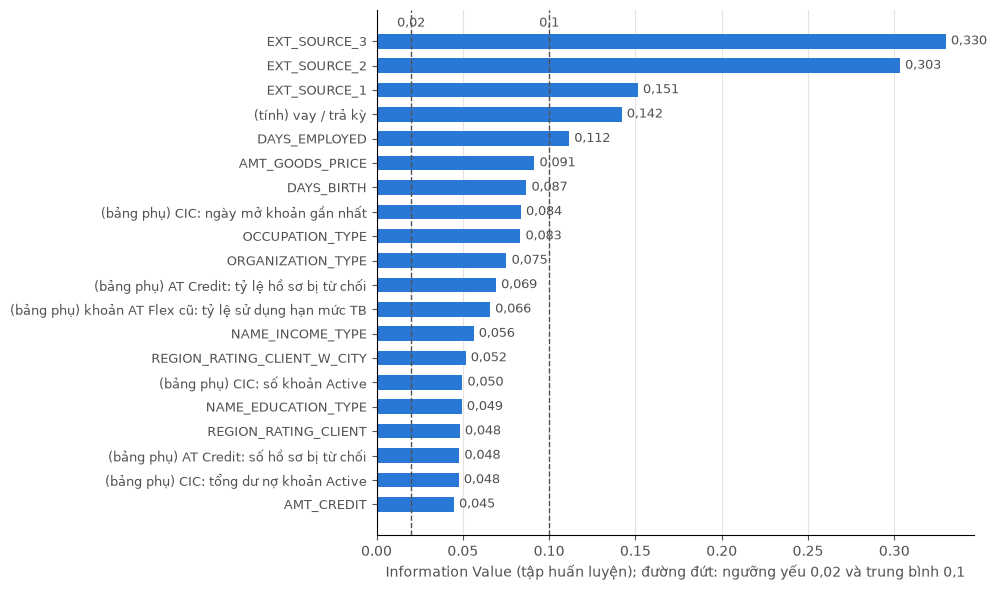

In [22]:
t = ivt.head(20).iloc[::-1]
fig, p = plt.subplots(figsize=(10, 6))
yy = np.arange(len(t))
p.barh(yy, t.IV, color=BLUE, height=0.6)
for v, lab in [(0.02, "0,02"), (0.1, "0,1")]:
    p.axvline(v, color=MUTED, lw=1, ls="--")
    p.text(v, len(t) - 0.4, lab, color=MUTED, fontsize=9, ha="center")
p.set_yticks(yy, t.index, fontsize=9, color=INK)
for i, v in enumerate(t.IV):
    p.text(v + 0.003, i, f"{v:.3f}".replace(".", ","), va="center", fontsize=9, color=MUTED)
p.set_xlabel("Information Value (tập huấn luyện); đường đứt: ngưỡng yếu 0,02 và trung bình 0,1", color=MUTED)
p.grid(axis="x", color=GRID, lw=0.8)
p.set_axisbelow(True)
p.tick_params(colors=MUTED)
p.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "ml_eda_iv.png", dpi=150)

## 7. Tương quan

**Cột số: Spearman** (tương quan thứ hạng): các cột tiền lệch phải và ngoại lai được giữ nguyên (B4), một giá trị 117 triệu có thể một mình kéo Pearson;
thứ hạng thì không. Mỗi cặp dùng các hồ sơ có đủ hai giá trị.

**Cột chữ: Cramér's V** = √(χ² / (n · (min(số hàng, số cột) − 1))) trên bảng chéo hai cột (ô trống là một giá trị): 0 là độc lập, 1 là cột này suy ra hoàn toàn cột kia.

In [23]:
num = a.drop(columns=["SK_ID_CURR", "TARGET"]).select_dtypes("number")
num = num.loc[:, num.nunique() > 1]
rk = num.rank()
ct = rk.corrwith(a.TARGET.rank()).dropna()
print(f"{num.shape[1]} cột số; |rho| với TARGET: < 0,01 ở {(ct.abs() < 0.01).sum()} cột; ≥ 0,05 ở {(ct.abs() >= 0.05).sum()}; ≥ 0,1 ở {(ct.abs() >= 0.1).sum()}")
ct.reindex(ct.abs().sort_values(ascending=False).index[:15]).to_frame("Spearman với TARGET")

105 cột số; |rho| với TARGET: < 0,01 ở 32 cột; ≥ 0,05 ở 11; ≥ 0,1 ở 3


,Spearman với TARGET
EXT_SOURCE_3,-0.1667
EXT_SOURCE_1,-0.1513
EXT_SOURCE_2,-0.1465
DAYS_EMPLOYED,0.0802
DAYS_BIRTH,0.0796
REGION_RATING_CLIENT_W_CITY,0.0613
REGION_RATING_CLIENT,0.0590
OWN_CAR_AGE,0.0541
DAYS_LAST_PHONE_CHANGE,0.0519
REG_CITY_NOT_WORK_CITY,0.0517


In [24]:
cm = rk.corr().abs()
up = cm.where(np.triu(np.ones(cm.shape, bool), 1)).stack()
is_build = up.index.map(lambda q: all(c.endswith(("_AVG", "_MODE", "_MEDI")) for c in q))
print(f"cặp |rho| ≥ 0,8: {(up >= 0.8).sum()}; ≥ 0,9: {(up >= 0.9).sum()} (cả hai là cột tòa nhà: {(is_build & (up >= 0.9)).sum()}); ≥ 0,95: {(up >= 0.95).sum()}")
up[~is_build & (up >= 0.9)].sort_values(ascending=False).to_frame("|rho|")

cặp |rho| ≥ 0,8: 106; ≥ 0,9: 71 (cả hai là cột tòa nhà: 67); ≥ 0,95: 57


,,|rho|
FLAG_EMP_PHONE,FLAG_NOT_EMPLOYED,0.9998
OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.9973
AMT_CREDIT,AMT_GOODS_PRICE,0.9849
REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,0.9504


In [25]:
cat = a.select_dtypes(exclude="number").fillna("(trống)")


def cramers_v(x1, x2):
    t = pd.crosstab(x1, x2)
    return np.sqrt(chi2_contingency(t, correction=False)[0] / (t.values.sum() * (min(t.shape) - 1)))


cv = pd.Series({(c1, c2): cramers_v(cat[c1], cat[c2]) for i, c1 in enumerate(cat) for c2 in cat.columns[i + 1:]})
print(f"{cat.shape[1]} cột chữ, {len(cv)} cặp; V ≥ 0,5: {(cv >= 0.5).sum()}; V ≥ 0,8: {(cv >= 0.8).sum()}")
cv[cv >= 0.3].sort_values(ascending=False).to_frame("Cramér's V")

15 cột chữ, 105 cặp; V ≥ 0,5: 3; V ≥ 0,8: 0


Cramér's V
WALLSMATERIAL_MODE EMERGENCYSTATE_MODE      0.6906
HOUSETYPE_MODE     EMERGENCYSTATE_MODE      0.6697
                   WALLSMATERIAL_MODE       0.5602
FONDKAPREMONT_MODE EMERGENCYSTATE_MODE      0.4613
NAME_INCOME_TYPE   ORGANIZATION_TYPE        0.4227
FONDKAPREMONT_MODE HOUSETYPE_MODE           0.3954
                   WALLSMATERIAL_MODE       0.3502
OCCUPATION_TYPE    ORGANIZATION_TYPE        0.3242

## 8. Thời điểm của lần quá hạn gần nhất

Theo đội hạng 5 và hạng 17: lần quá hạn cách đây 5 năm nặng nhẹ khác lần cách đây 1 tháng. Với 4 bảng có quá hạn, chia khách theo
số tháng từ lần quá hạn gần nhất đến ngày nộp: ≤ 12 tháng, 13–36 tháng, > 36 tháng, chưa từng (có dữ liệu nhưng không quá hạn), không có dữ liệu.
Mốc quá hạn: ≥ 10 ngày (ranh giới nhóm 2) ở 3 bảng của AT Credit; STATUS 1–5 ở CIC theo tháng (STATUS không tách được mốc 10 ngày, bảng khớp mục 7).

In [26]:
def recency(months, covered):
    g = pd.Series("không có dữ liệu", index=y.index)
    g[y.index.isin(covered)] = "chưa từng"
    mo = months.reindex(y.index).dropna()
    g[mo.index] = pd.cut(mo, [-1, 12, 36, 10_000], labels=["≤ 12 tháng", "13–36 tháng", "> 36 tháng"]).astype(str)
    return g


order = ["≤ 12 tháng", "13–36 tháng", "> 36 tháng", "chưa từng", "không có dữ liệu"]
rec = {c: recency(*v) for c, v in last.items()}
pd.concat({c: rate(g, y, 0).reindex(order) for c, g in rec.items()})

số hồ sơ  TARGET
CIC tháng: STATUS 1–5               ≤ 12 tháng           12644  0.1183
                                    13–36 tháng           7173  0.0864
                                    > 36 tháng            4965  0.0737
                                    chưa từng            48884  0.0716
                                    không có dữ liệu    172342  0.0805
khoản trả góp cũ: tháng SK_DPD ≥ 10 ≤ 12 tháng            2275  0.1749
                                    13–36 tháng           4184  0.1458
                                    > 36 tháng           14477  0.0784
                                    chưa từng           210620  0.0795
                                    không có dữ liệu     14452  0.0668
khoản AT Flex cũ: tháng SK_DPD ≥ 10 ≤ 12 tháng            1196  0.1279
                                    13–36 tháng            889  0.0990
                                    > 36 tháng            1232  0.0706
                                    chưa từng            66366  0.0861
                                    không có dữ liệu    176325  0.0784
kỳ trả nợ cũ: quá hạn ≥ 10 ngày     ≤ 12 tháng            7514  0.1795
                                    13–36 tháng          15226  0.1215
                                    > 36 tháng           32805  0.0732
                                    chưa từng           177777  0.0759
                                    không có dữ liệu     12686  0.0598

In [27]:
pd.Series({c: woe_table(g.values, a.TARGET.values).IV_i.sum() for c, g in rec.items()}).to_frame("IV của biến thời điểm (5 nhóm)")

,IV của biến thời điểm (5 nhóm)
CIC tháng: STATUS 1–5,0.0146
khoản trả góp cũ: tháng SK_DPD ≥ 10,0.0228
khoản AT Flex cũ: tháng SK_DPD ≥ 10,0.0040
kỳ trả nợ cũ: quá hạn ≥ 10 ngày,0.0618


Đối chiếu riêng tháng `SK_DPD` > 90 (bảng mục 5 cho thấy "từng có" ở khoản AT Flex cũ lại thấp hơn mức chung): dư nợ của những tháng đó,
vị trí trong vòng đời khoản vay, và TARGET theo thời điểm.

In [28]:
for name, dm in monthly.items():
    h = dm[dm.SK_DPD > 90]
    extra = (f"dư nợ trung vị {h.AMT_BALANCE.median():,.0f} đơn vị" if name == "credit_card_balance"
             else f"sau kỳ cuối (CNT_INSTALMENT_FUTURE = 0) {(h.CNT_INSTALMENT_FUTURE == 0).mean():.1%}")
    print(f"{name}: {len(h):,} tháng SK_DPD > 90; SK_DPD trung vị {h.SK_DPD.median():.0f} ngày; MONTHS_BALANCE trung vị {h.MONTHS_BALANCE.median():.0f}; {extra}")
    g = recency(-h.groupby("SK_ID_CURR").MONTHS_BALANCE.max(), dm.SK_ID_CURR.unique())
    print(rate(g, y, 0).reindex(order).to_string(), "\n")

POS_CASH_balance: 84,252 tháng SK_DPD > 90; SK_DPD trung vị 726 ngày; MONTHS_BALANCE trung vị -53; sau kỳ cuối (CNT_INSTALMENT_FUTURE = 0) 99.9%
                  số hồ sơ  TARGET
≤ 12 tháng             746  0.1193
13–36 tháng            368  0.1114
> 36 tháng            2605  0.0710
chưa từng           227837  0.0815
không có dữ liệu     14452  0.0668 

credit_card_balance: 33,883 tháng SK_DPD > 90; SK_DPD trung vị 640 ngày; MONTHS_BALANCE trung vị -29; dư nợ trung vị 213 đơn vị
                  số hồ sơ  TARGET
≤ 12 tháng             685  0.0788
13–36 tháng            296  0.0642
> 36 tháng             247  0.0405
chưa từng            68455  0.0871
không có dữ liệu    176325  0.0784 



## 9. Tóm tắt, chuyển sang B6

(Số cụ thể ở output các ô trên.)

1. **Thiếu không phải MCAR** ở mọi cột thiếu > 1% và ở bảng phụ → LightGBM giữ ô trống; LR thêm cờ thiếu khi điền; không ghi 0 cho khách không có dữ liệu bảng phụ.
2. **IV**: xếp hạng sức phân biệt từng cột để đọc kết quả mô hình sau này; không cột nào > 0,5 thì không có dấu hiệu rò rỉ đơn biến. IV là đơn biến nên **không** dùng để loại cột.
3. **Spearman/Cramér's V**: nhóm 47 cột tòa nhà và các cặp gần trùng → quy tắc loại cột trùng thông tin ở B6 (kèm VIF cho LR).
4. **Quan hệ không đơn điệu** của cột số tiền và "vay / trả kỳ" → bất lợi cho LR; "vay / trả kỳ" mang thông tin kỳ hạn/lãi suất.
5. **Dấu hiệu quá hạn phải kèm thời điểm** (mục 8).
6. Mười cột gần hằng số (B4) quyết định cùng các quy tắc trên.